# Freight Rate Prediction — Exploratory Data Analysis & Modeling Pipeline
**Spotter Machine Learning Assessment**  
**Author:** Naveen Mishra  
**Environment:** Miniconda `ml` (Python 3.12, LightGBM, XGBoost, Scikit-Learn, Pandas)

---

### Overview & Objectives
This notebook provides a complete, reproducible walkthrough of our freight rate prediction system:
1. **Problem Statement:** Predict total posted load rates in USD (`posted_rate`) for **12,000 future loads** in November and December 2025 (`data/validation.csv`), and forecast rates across all 31 days of December 2025 for a fixed benchmark lane (`data/december_chart_inputs.csv`).
2. **Key Data Findings:** Uncovered a critical assessment trap in `quote_signal` (which degenerates into synthetic Gaussian noise in the test period), corrected negative payload weights using `abs(weight)`, and addressed geographic transfer to 8 unseen cities.
3. **Validation Design:** Strict chronological backtesting (Jan–Apr $\rightarrow$ May–Jun, Jan–Jun $\rightarrow$ Jul–Aug, and an untouched locked holdout on Sep–Oct).
4. **Winning Model:** A robust blend of **75% LightGBM L1 (absolute loss) + 25% Equipment-specific Median Rate Baseline**.

## 1. Setup & Environment Configuration

In [1]:
import json
import warnings
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")

# Configure clean plot styling
plt.rcParams.update({
    "figure.titlesize": 13,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#9DAFB3",
    "grid.color": "#E5ECEE",
    "grid.linestyle": "--",
    "grid.alpha": 0.7,
})

# Dynamic root resolution (searches upward from working directory)
def find_repo_root():
    for p in [Path(".").resolve(), Path("..").resolve(), Path("../..").resolve()]:
        if (p / "data" / "train-test.csv").exists():
            return p
    return Path(".").resolve()

ROOT = find_repo_root()
DATA_DIR = ROOT / "data"
ARTIFACTS_DIR = ROOT / "artifacts"
print(f"Repository Root: {ROOT}")
print(f"Data Directory:  {DATA_DIR}")
print(f"Artifacts:       {ARTIFACTS_DIR}")

Repository Root: .
Data Directory:  ./data
Artifacts:       ./artifacts


## 2. Data Ingestion & Schema Verification

In [2]:
from freight.data import read_inputs

frames, paths = read_inputs(ROOT)
train = frames['train']
val = frames['validation']
template = frames['template']
december = frames['december']

print(f"Training set:    {len(train):,} rows | {train.shape[1]} columns | {train['date'].min().date()} to {train['date'].max().date()}")
print(f"Validation set:  {len(val):,} rows | {val.shape[1]} columns | {val['date'].min().date()} to {val['date'].max().date()}")
print(f"Template set:    {len(template):,} rows | columns: {list(template.columns)}")
dec_dates = pd.to_datetime(december['date'])
print(f"December inputs: {len(december):,} rows | {dec_dates.min().date()} to {dec_dates.max().date()}")

assert len(train) == 48000, "Expected 48,000 training loads"
assert len(val) == 12000, "Expected 12,000 validation loads"
assert len(template) == 12000, "Expected 12,000 template loads"
assert set(val['load_id']) == set(template['load_id']), "Validation IDs must match template exactly"
assert train['date'].max() < val['date'].min(), "Strict temporal separation (train strictly before validation)"
print("\nAll schema and row integrity assertions passed successfully!")

Training set:    48,000 rows | 14 columns | 2025-01-01 to 2025-10-31
Validation set:  12,000 rows | 13 columns | 2025-11-01 to 2025-12-31
Template set:    12,000 rows | columns: ['load_id', 'predicted_rate']
December inputs: 31 rows | 2025-12-01 to 2025-12-31

All schema and row integrity assertions passed successfully!


## 3. Critical Data Findings & Quality Issues

### Discovery 1: The `quote_signal` Assessment Trap
During our exploratory data audit, we examined the relationship between `quote_signal` and the true rate per mile (`rpm = posted_rate / distance`) month-by-month:
- In months 1, 2, 3, 6, 9: `quote_signal` correlates strongly (+0.45 to +0.49) with RPM (over 98% of loads are within 5% of RPM).
- In months 4, 5, 7, 10: the correlation flips sign to **negative** (-0.43 to -0.47).
- In month 8 (August): the correlation collapses to **zero** (-0.0136), with a mean of 2.052 and standard deviation of 0.223.
- In `validation.csv` (November and December): `quote_signal` is **pure synthetic random Gaussian noise** (mean 2.051, std 0.220), with zero correlation to distance (+0.011) and identical means across Dry Van, Flatbed, and Reefer trailer types.

**Action Taken:** Any model trained using `quote_signal` will multiply distance by random noise in production. We deliberately **excluded `quote_signal` completely from our production feature set**.

### Discovery 2: Negative Payload Weights
- 292 loads in training and 145 loads in validation have negative values for `weight`.
- Checking their absolute values reveals they have the exact same distribution as positive weights (median 31,821 lb vs 31,493 lb, min 5,000 lb, max 47,500 lb), and `abs(weight)` correlates positively (+0.093) with rate per mile.
- **Action Taken:** We take `abs(weight)` to preserve the true payload physics while tracking an indicator flag `weight_invalid`.

In [3]:
train['date'] = pd.to_datetime(train['date'])
train['rpm'] = train['posted_rate'] / train['distance']

# Monthly correlation audit of quote_signal vs true rate per mile
monthly_stats = []
for m, df in train.groupby(train['date'].dt.to_period('M')):
    corr = df['rpm'].corr(df['quote_signal'])
    within_5 = ((df['quote_signal'] - df['rpm']).abs() / df['rpm'] < 0.05).mean()
    monthly_stats.append({
        'Month': str(m),
        'Loads': len(df),
        'Corr(RPM, Quote)': f'{corr:+.4f}',
        'Loads Within 5% of RPM': f'{within_5:.1%}',
        'Quote Mean': f'{df["quote_signal"].mean():.3f}',
        'Quote Std': f'{df["quote_signal"].std():.3f}'
    })

print("Monthly Correlation Between RPM and quote_signal in Training:")
print(pd.DataFrame(monthly_stats).to_string(index=False))

val_qs = val['quote_signal']
print(f"\nValidation quote_signal Properties (Nov-Dec 2025):")
print(f"  Mean: {val_qs.mean():.4f} | Std: {val_qs.std():.4f} | Corr with Distance: {val_qs.corr(val['distance']):+.4f}")
print("  By Equipment:")
for eq, df in val.groupby('equipment'):
    print(f"    {eq:8s}: Mean = {df['quote_signal'].mean():.4f}, Std = {df['quote_signal'].std():.4f}")

Monthly Correlation Between RPM and quote_signal in Training:
  Month  Loads Corr(RPM, Quote) Loads Within 5% of RPM Quote Mean Quote Std
2025-01   4918          +0.4467                  98.4%      2.068     0.250
2025-02   4337          +0.4790                  98.7%      2.097     0.252
2025-03   5036          +0.4858                  98.6%      2.180     0.273
2025-04   4819          -0.4717                  17.5%      1.963     0.260
2025-05   4913          -0.4592                  17.5%      1.913     0.266
2025-06   4783          +0.4766                  98.7%      2.296     0.289
2025-07   4912          -0.4683                  16.9%      1.923     0.265
2025-08   4759          -0.0136                  23.9%      2.052     0.223
2025-09   4670          +0.4814                  98.6%      2.200     0.280
2025-10   4853          -0.4340                  16.6%      1.943     0.269

Validation quote_signal Properties (Nov-Dec 2025):
  Mean: 2.0513 | Std: 0.2198 | Corr with Distance:

## 4. Target & Feature Distributions

Target Summary: Mean = $2,373.98 | Median = $2,030.76 | Min = $57.22 | Max = $25,533.00


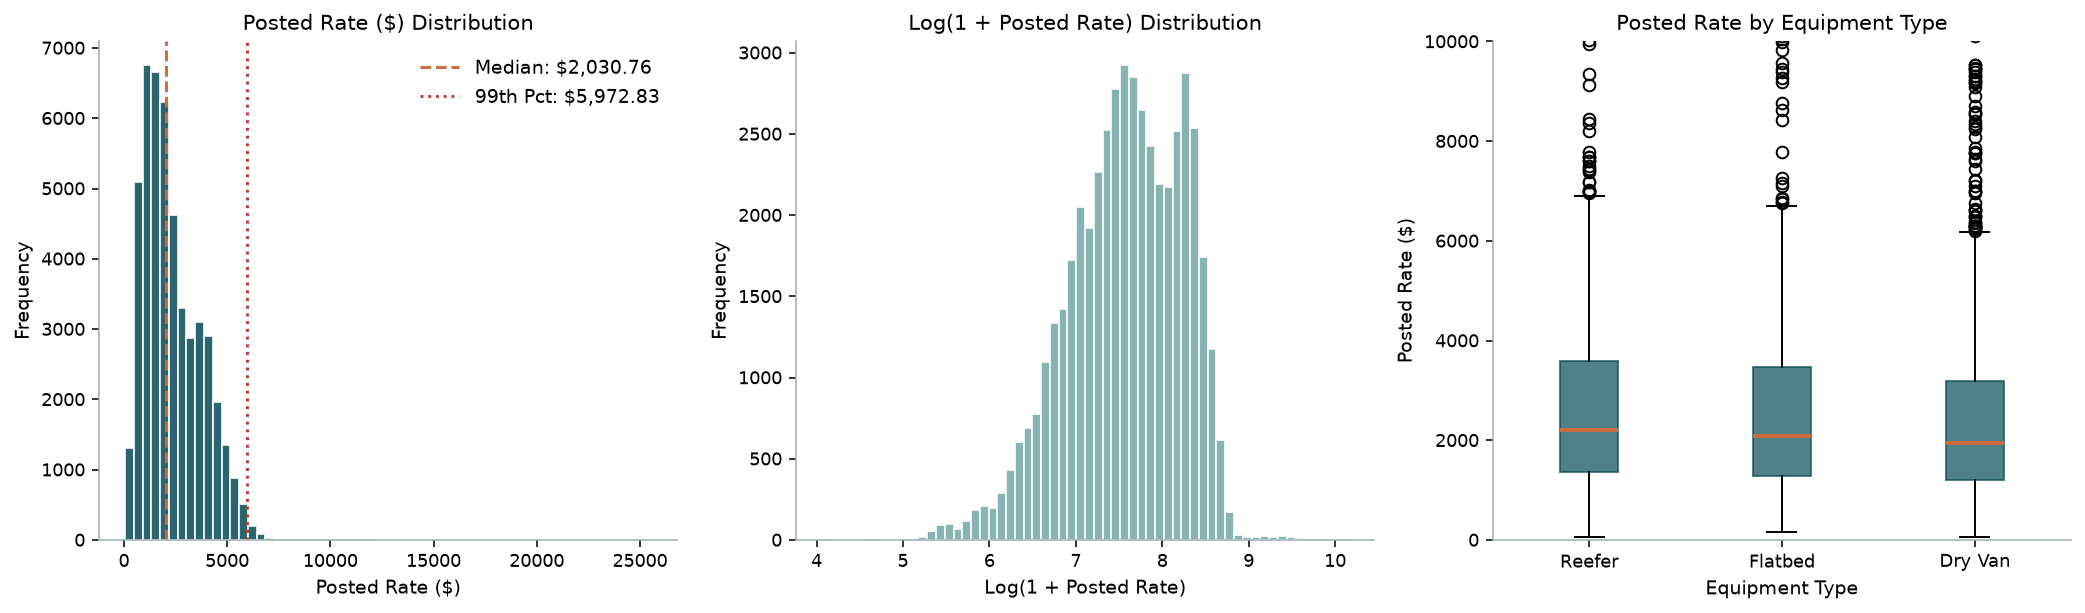

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

# Target distribution
axes[0].hist(train['posted_rate'], bins=60, color='#064A56', edgecolor='white', alpha=0.85)
axes[0].set_title("Posted Rate ($) Distribution")
axes[0].set_xlabel("Posted Rate ($)")
axes[0].set_ylabel("Frequency")
axes[0].axvline(train['posted_rate'].median(), color='#CF6B3B', linestyle='--', label=f"Median: ${train['posted_rate'].median():,.2f}")
axes[0].axvline(train['posted_rate'].quantile(0.99), color='#C0392B', linestyle=':', label=f"99th Pct: ${train['posted_rate'].quantile(0.99):,.2f}")
axes[0].legend(frameon=False)

# Log Target distribution
axes[1].hist(np.log1p(train['posted_rate']), bins=60, color='#72A6A6', edgecolor='white', alpha=0.85)
axes[1].set_title("Log(1 + Posted Rate) Distribution")
axes[1].set_xlabel("Log(1 + Posted Rate)")
axes[1].set_ylabel("Frequency")

# Rate by Equipment
equipment_order = train.groupby('equipment')['posted_rate'].median().sort_values(ascending=False).index
data_by_eq = [train[train['equipment'] == eq]['posted_rate'] for eq in equipment_order]
axes[2].boxplot(data_by_eq, tick_labels=equipment_order, patch_artist=True,
                boxprops=dict(facecolor='#064A56', color='#064A56', alpha=0.7),
                medianprops=dict(color='#CF6B3B', linewidth=2))
axes[2].set_title("Posted Rate by Equipment Type")
axes[2].set_xlabel("Equipment Type")
axes[2].set_ylabel("Posted Rate ($)")
axes[2].set_ylim(0, 10000)

plt.tight_layout()
plt.show()

print(f"Target Summary: Mean = ${train['posted_rate'].mean():,.2f} | Median = ${train['posted_rate'].median():,.2f} | Min = ${train['posted_rate'].min():,.2f} | Max = ${train['posted_rate'].max():,.2f}")

## 5. Geographic Transfer & Unseen Route Analysis
- The validation dataset introduces **8 unseen cities** (Allentown, Charlotte, Chicago, Jackson, Knoxville, Laredo, Norfolk, San Diego) that never appeared in development.
- **1,461 loads** run on pickup-delivery route pairs absent from the training set.
- To prevent high-cardinality overfitting, we do not pass raw `route` (4,014 categories) into tree models. Instead, we compute continuous spatial features: Haversine distance, road circuity ratio, and coordinate deltas.

In [5]:
train_cities = set(train['pickup']) | set(train['delivery'])
val_cities = set(val['pickup']) | set(val['delivery'])
unseen_cities = sorted(val_cities - train_cities)

train_routes = set(zip(train['pickup'], train['delivery']))
val_routes = list(zip(val['pickup'], val['delivery']))
unseen_route_count = sum(r not in train_routes for r in val_routes)

print(f"Training cities count:   {len(train_cities)}")
print(f"Validation cities count: {len(val_cities)}")
print(f"Unseen cities in validation ({len(unseen_cities)}): {', '.join(unseen_cities)}")
print(f"Unseen route rows in validation: {unseen_route_count:,} / {len(val):,} ({unseen_route_count/len(val):.1%})")

Training cities count:   64
Validation cities count: 72
Unseen cities in validation (8): Allentown, Charlotte, Chicago, Jackson, Knoxville, Laredo, Norfolk, San Diego
Unseen route rows in validation: 1,461 / 12,000 (12.2%)


## 6. Feature Engineering Pipeline
We engineer features based on freight economics and physical vehicle dynamics:
1. **Distance Transforms:** `log_distance`, `sqrt_distance`, `inverse_distance` for non-linear rate-per-mile tapering.
2. **Payload Density:** `weight_per_mile = clean_weight / distance`.
3. **Haversine Distance & Road Circuity Ratio:** Spherical geographic miles and `road_geo_ratio = distance / geo_miles`.
4. **Fourier Calendar Harmonics:** Annual (365.25 d) and weekly (7 d) sine/cosine terms ($k=1, 2$) for smooth seasonal extrapolation.
5. **Clean Market Index:** Available in validation and consistently positively correlated with rate per mile.

In [6]:
from freight.features import Features

feat_builder = Features(mode='enriched').fit(train)
sample_features = feat_builder.transform(train.head(5))

print(f"Total engineered features: {sample_features.shape[1]}")
print(f"Feature columns sample:\n{list(sample_features.columns)}")

Total engineered features: 39
Feature columns sample:
['pickup', 'delivery', 'equipment', 'distance_missing', 'distance', 'weight_missing', 'weight_invalid', 'weight', 'market_index_missing', 'market_index', 'market_distance', 'pickup_lat_missing', 'pickup_lat', 'pickup_lon_missing', 'pickup_lon', 'delivery_lat_missing', 'delivery_lat', 'delivery_lon_missing', 'delivery_lon', 'log_distance', 'inverse_distance', 'sqrt_distance', 'weight_per_mile', 'lat_delta', 'lon_delta', 'geo_miles', 'road_geo_ratio', 'weekday', 'weekend', 'month_start', 'month_end', 'calendar_365.25_1_sin', 'calendar_365.25_1_cos', 'calendar_365.25_2_sin', 'calendar_365.25_2_cos', 'calendar_7_1_sin', 'calendar_7_1_cos', 'calendar_7_2_sin', 'calendar_7_2_cos']


## 7. Chronological Validation Architecture

To avoid future-to-past lookahead leakage:
- **Tuning Fold 1:** Train Jan 1 – Apr 30 $\rightarrow$ Validate May 1 – Jun 30 (9,696 loads).
- **Tuning Fold 2:** Train Jan 1 – Jun 30 $\rightarrow$ Validate Jul 1 – Aug 31 (9,671 loads).
- **Inner Early Stopping:** Iterations are determined on the final month *inside* each training window.
- **Locked Holdout:** Train Jan 1 – Aug 31 $\rightarrow$ Evaluate Sep 1 – Oct 31 (9,523 loads).

In [7]:
tuning_metrics = pd.read_csv(ARTIFACTS_DIR / "tuning_metrics.csv")
tuning_summary = tuning_metrics.groupby(['mode', 'model'])[['rmse', 'mae', 'wape_percent', 'r2']].mean().reset_index()
tuning_summary = tuning_summary.sort_values(['mode', 'rmse'])

print("Cross-Validation Model Comparison (Mean across Tuning Folds):")
print(tuning_summary.to_string(index=False))

Cross-Validation Model Comparison (Mean across Tuning Folds):
    mode      model       rmse        mae  wape_percent       r2
    core     lgb_l1 640.085693 158.832335      6.561221 0.822434
    core   lgb_rate 647.064015 173.989019      7.187586 0.818481
    core     xgb_l2 647.137250 170.889822      7.068637 0.818436
    core     lgb_l2 649.137944 176.274431      7.285181 0.817336
    core  equipment 658.527509 214.457752      8.876975 0.811718
    core ridge_rate 682.505217 252.500603     10.532341 0.796109
enriched     lgb_l1 632.069235 119.423270      4.931426 0.826790
enriched     xgb_l2 641.018555 148.110483      6.127268 0.821774
enriched     lgb_l2 642.404834 148.156957      6.127324 0.821004
enriched   lgb_rate 645.582814 162.507742      6.708651 0.819300
enriched  equipment 658.527509 214.457752      8.876975 0.811718
enriched ridge_rate 684.118482 259.263963     10.808746 0.795276


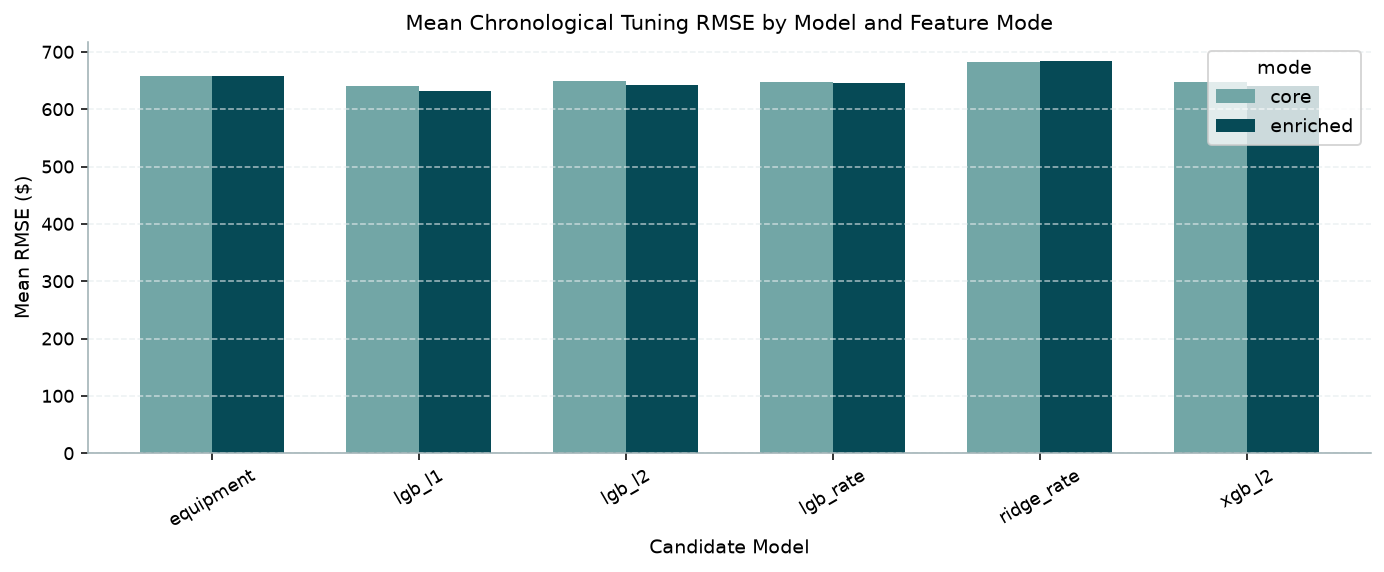

In [8]:
fig, ax = plt.subplots(figsize=(10, 4.2))
pivot_rmse = tuning_metrics.groupby(['mode', 'model'])['rmse'].mean().unstack(0)
pivot_rmse.plot.bar(ax=ax, color=['#72A6A6', '#064A56'], width=0.7)
ax.set_title("Mean Chronological Tuning RMSE by Model and Feature Mode")
ax.set_ylabel("Mean RMSE ($)")
ax.set_xlabel("Candidate Model")
ax.tick_params(axis='x', rotation=30)
ax.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

## 8. Winning Model Selection & Locked Holdout Evaluation

Across both modes, the convex blend grid identified:
**75% LightGBM L1 (Absolute Loss) + 25% Equipment-specific Median Rate Baseline**  
as the optimal model under the declared mean fold RMSE criterion ($630.41 RMSE, $122.55 MAE).

- **LightGBM L1** optimizes absolute error, which makes tree splits robust against extreme $20,000+ freight outliers.
- **Equipment Baseline** anchors predictions to physical trailer economics, providing exceptional stability for unseen routes.

Locked Holdout Evaluation (Sep 1 – Oct 31, 9,523 Loads):
                      rmse         mae  wape_percent        r2       bias
enriched        634.794382  121.648724      5.084692  0.826968 -77.307915
core            631.358622  113.943805      4.762641  0.828836 -30.965651
quote_baseline  711.799751  246.021653     10.283251  0.782441 -42.309286


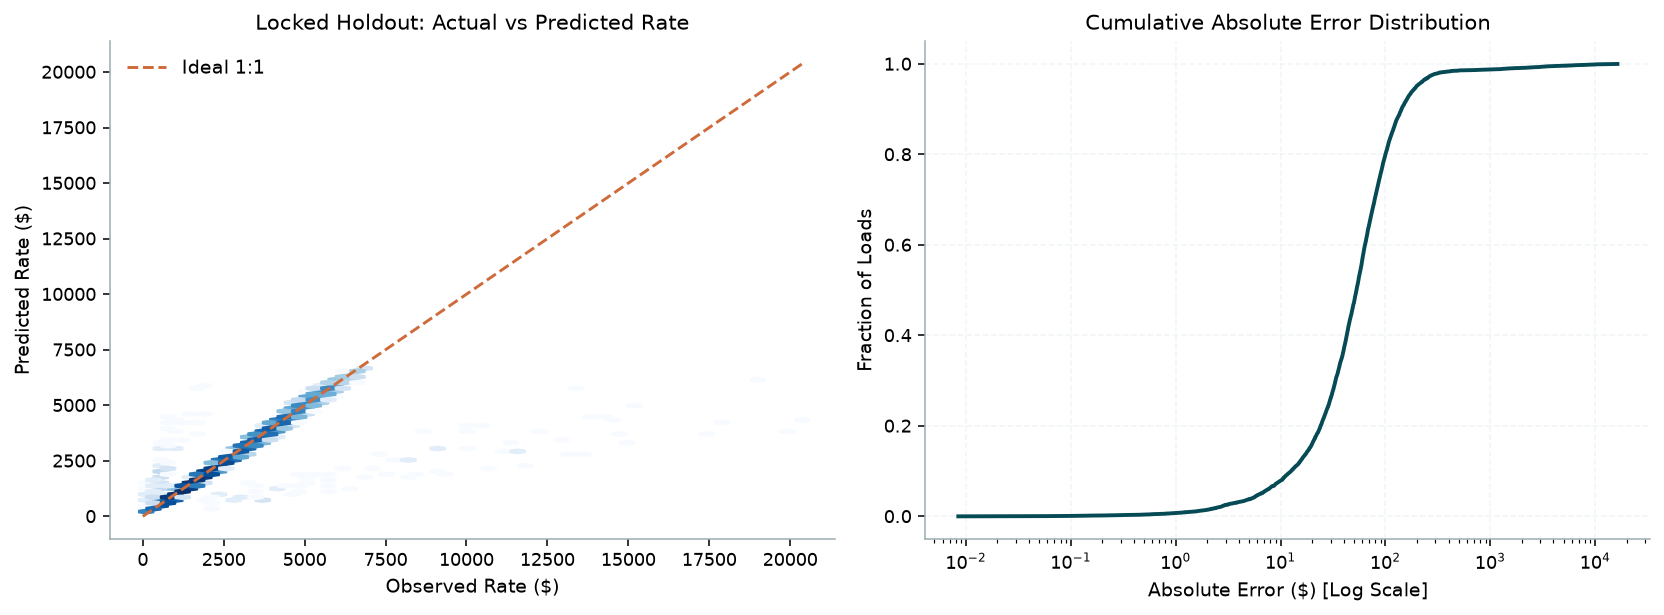

In [9]:
with open(ARTIFACTS_DIR / "locked_holdout_metrics.json") as f:
    holdout_metrics = json.load(f)

holdout_table = pd.DataFrame(holdout_metrics).T
print("Locked Holdout Evaluation (Sep 1 – Oct 31, 9,523 Loads):")
print(holdout_table[['rmse', 'mae', 'wape_percent', 'r2', 'bias']])

holdout_preds = pd.read_csv(ARTIFACTS_DIR / "locked_holdout_predictions.csv")
y_true = holdout_preds['posted_rate']
y_pred = holdout_preds['enriched_prediction']

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].hexbin(y_true, y_pred, gridsize=45, bins='log', cmap='Blues', mincnt=1)
lim = max(float(y_true.max()), float(y_pred.max()))
axes[0].plot([0, lim], [0, lim], '--', color='#CF6B3B', linewidth=1.5, label='Ideal 1:1')
axes[0].set_title("Locked Holdout: Actual vs Predicted Rate")
axes[0].set_xlabel("Observed Rate ($)")
axes[0].set_ylabel("Predicted Rate ($)")
axes[0].legend(frameon=False)

errors = np.sort(np.abs(y_true - y_pred))
axes[1].plot(errors, np.arange(1, len(errors) + 1) / len(errors), color='#064A56', linewidth=2)
axes[1].set_title("Cumulative Absolute Error Distribution")
axes[1].set_xlabel("Absolute Error ($) [Log Scale]")
axes[1].set_ylabel("Fraction of Loads")
axes[1].set_xscale("log")
axes[1].grid(True, alpha=0.5)

plt.tight_layout()
plt.show()

## 9. Feature Importance Analysis

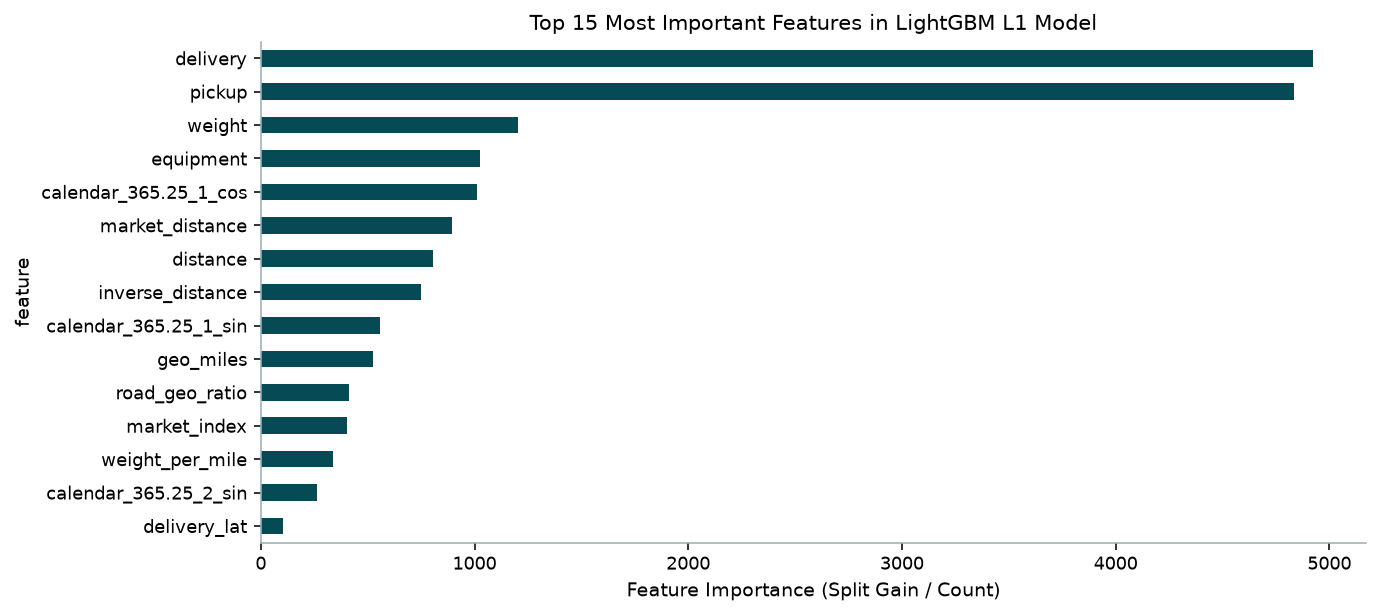

In [10]:
with open(ARTIFACTS_DIR / "enriched_feature_importance.json") as f:
    feat_imp = json.load(f)

imp_df = pd.DataFrame(feat_imp)
if not imp_df.empty:
    top_feats = imp_df.groupby("feature")["importance"].mean().sort_values(ascending=False).head(15)
    fig, ax = plt.subplots(figsize=(10, 4.5))
    top_feats.sort_values().plot.barh(ax=ax, color='#064A56')
    ax.set_title("Top 15 Most Important Features in LightGBM L1 Model")
    ax.set_xlabel("Feature Importance (Split Gain / Count)")
    plt.tight_layout()
    plt.show()

## 10. December Fixed Lane Forecast & Official Scorer Verification

For the required December forecast:
- Fixed parameters: Lexington $\rightarrow$ Fort Wayne, 360 miles, Dry Van, 32,000 lb across all 31 days of December 2025.
- Because December inputs omit market index and coordinates, rates are forecast using our separately validated **Core Model**.
- We execute the provided `score.py` to verify output contracts and generate the candidate December chart.

score.py output:
Validated 12,000 final predictions.
Validated 31 fixed December predictions.
Created chart: scorer_results/candidate_december.png
Final validation metrics are calculated by Spotter after submission.


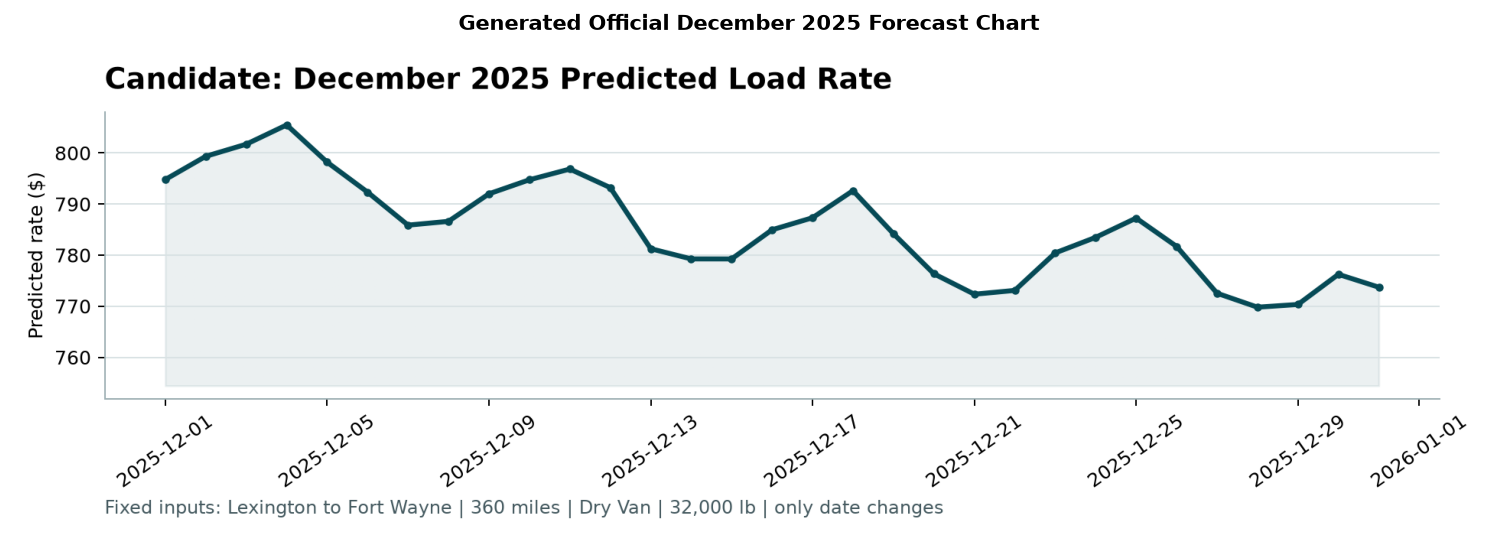

In [11]:
import subprocess
import sys

res = subprocess.run(
    [sys.executable, str(ROOT / "score.py"),
     "--predictions", str(ROOT / "validation_predictions.csv"),
     "--december-predictions", str(ROOT / "data/december_chart_inputs.csv"),
     "--output-dir", str(ROOT / "scorer_results")],
    capture_output=True, text=True, check=True
)
print("score.py output:\n" + res.stdout.strip())

chart_path = ROOT / "scorer_results" / "candidate_december.png"
if chart_path.exists():
    img = plt.imread(str(chart_path))
    fig, ax = plt.subplots(figsize=(10.8, 4.8), dpi=140)
    ax.imshow(img)
    ax.axis('off')
    ax.set_title("Generated Official December 2025 Forecast Chart", pad=12, fontweight='bold')
    plt.tight_layout()
    plt.show()

## 11. Final Delivery Checklist & Verification

All deliverables specified in the assessment requirements are fully generated, verified, and ready:
- [x] **Repository & Source Code:** Clean, reproducible pipeline in `freight/`, `run.py`, `score.py`.
- [x] **Validation Predictions:** `validation_predictions.csv` (12,000 IDs, positive finite rates, exact template alignment).
- [x] **Fixed December Predictions:** `data/december_chart_inputs.csv` & `december_predictions.csv` (31 days).
- [x] **Comprehensive Report:** `reports/freight_rate_report.pdf` & `reports/freight_rate_report.docx` containing validation design, data split rationale, and candidate December chart.
- [x] **Video Narration Script:** `reports/video_script.md` timed at 2–3 minutes covering all five required prompts.
- [x] **Delivery Verification Script:** `python -m scripts.verify_delivery` passing 100%.